# Real-Time Hand Gesture Recognition

Rule-based hand gesture recognition using MediaPipe hand landmarks.


In [53]:
import numpy as np 
import matplotlib.pyplot as plt

import mediapipe as mp
import cv2

from collections import Counter

## MediaPipe Hand Tracking

In [54]:
medhands=mp.solutions.hands

hands = medhands.Hands(
    static_image_mode=False,
    max_num_hands=2, 
    min_detection_confidence=0.5,
    min_tracking_confidence=0.5
)

mpDraw = mp.solutions.drawing_utils

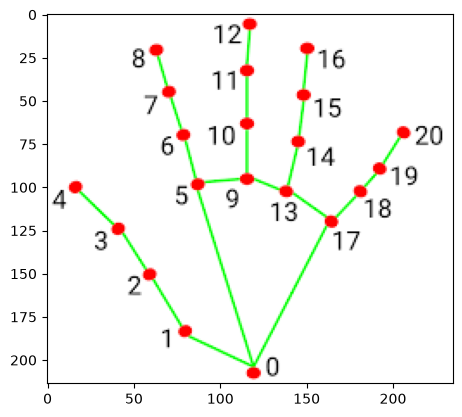

In [55]:
im= plt.imread("images.png")

plt.imshow(im)


## Landmark Definitions

In [56]:
LANDMARKS = {
    "WRIST": 0,

    "THUMB_CMC": 1,
    "THUMB_MCP": 2,
    "THUMB_IP": 3,
    "THUMB_TIP": 4,

    "INDEX_MCP": 5,
    "INDEX_PIP": 6,
    "INDEX_DIP": 7,
    "INDEX_TIP": 8,

    "MIDDLE_MCP": 9,
    "MIDDLE_PIP": 10,
    "MIDDLE_DIP": 11,
    "MIDDLE_TIP": 12,

    "RING_MCP": 13,
    "RING_PIP": 14,
    "RING_DIP": 15,
    "RING_TIP": 16,

    "LITTLE_MCP": 17,
    "LITTLE_PIP": 18,
    "LITTLE_DIP": 19,
    "LITTLE_TIP": 20
}

print(LANDMARKS['INDEX_TIP'])

8


In [57]:
FINGER_LANDMARKS = {
    "THUMB": [1, 2, 3, 4],
    "INDEX": [5, 6, 7, 8],
    "MIDDLE": [9, 10, 11, 12],
    "RING": [13, 14, 15, 16],
    "LITTLE": [17, 18, 19, 20]
}

## Finger State Functions   

In [58]:
def is_finger_open(mcp, pip, dip):
    angle = calculate_angle_3d(mcp, pip, dip)

    return angle > 150

## Angle-Based Finger Detection


In [59]:
def calculate_angle_3d(a, b, c):
    ba = np.array([
        a.x - b.x,
        a.y - b.y,
        a.z - b.z
    ])

    bc = np.array([
        c.x - b.x,
        c.y - b.y,
        c.z - b.z
    ])

    cosine_angle = np.dot(ba, bc) / (
        np.linalg.norm(ba) * np.linalg.norm(bc)
    )

    cosine_angle = np.clip(cosine_angle, -1.0, 1.0)

    angle = np.degrees(np.arccos(cosine_angle))

    return angle

## Gesture Recognition Engine

In [60]:
def identify_gesture(finger_state, thumb_direction):

    # FIST
    if not any(finger_state.values()):
        return "FIST"

    # OPEN PALM
    if all(finger_state.values()):
        return "OPEN_PALM"

    # POINTING
    if (
        finger_state["INDEX"]
        and not finger_state["MIDDLE"]
        and not finger_state["RING"]
        and not finger_state["LITTLE"]
    ):
        return "POINTING"

    # VICTORY
    if (
        finger_state["INDEX"]
        and finger_state["MIDDLE"]
        and not finger_state["RING"]
        and not finger_state["LITTLE"]
    ):
        return "VICTORY"

    # CALL ME
    if (
        finger_state["THUMB"]
        and finger_state["LITTLE"]
        and not finger_state["INDEX"]
        and not finger_state["MIDDLE"]
        and not finger_state["RING"]
    ):
        return "CALL_ME"

    # THUMBS UP
    if (
        finger_state["THUMB"]
        and thumb_direction == "UP"
        and not finger_state["INDEX"]
        and not finger_state["MIDDLE"]
        and not finger_state["RING"]
        and not finger_state["LITTLE"]
    ):
        return "THUMBS_UP"

    # THUMBS DOWN
    if (
        finger_state["THUMB"]
        and thumb_direction == "DOWN"
        and not finger_state["INDEX"]
        and not finger_state["MIDDLE"]
        and not finger_state["RING"]
        and not finger_state["LITTLE"]
    ):
        return "THUMBS_DOWN"

    return "UNKNOWN"

In [61]:
def is_thumb_open(landmarks):

    if landmarks[12].y < landmarks[20].y:

        if landmarks[4].y > landmarks[3].y:
            return False
        else:
            return True

    else:

        if landmarks[4].y < landmarks[3].y:
            return False
        else:
            return True

In [62]:
def get_thumb_direction(landmarks):

    thumb_mcp = landmarks[LANDMARKS["THUMB_MCP"]]
    thumb_tip = landmarks[LANDMARKS["THUMB_TIP"]]

    dy = thumb_tip.y - thumb_mcp.y

    if dy < 0:
        return "UP"

    elif dy > 0:
        return "DOWN"

    return "UNKNOWN"

## Webcam Capture

In [ ]:
video=cv2.VideoCapture(0)

gesture_history = []

while True:
    suc,img=video.read()
    if not suc:
        break
    
    img1=cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
    res=hands.process(img1)

    if res.multi_hand_landmarks:
        for handlms in res.multi_hand_landmarks:

                # Finger states
                finger_state = {
                    "THUMB": is_thumb_open(handlms.landmark),

                    "INDEX": is_finger_open(
                            handlms.landmark[LANDMARKS["INDEX_MCP"]],
                            handlms.landmark[LANDMARKS["INDEX_PIP"]],
                            handlms.landmark[LANDMARKS["INDEX_DIP"]]
                        ),

                    "MIDDLE": is_finger_open(
                            handlms.landmark[LANDMARKS["MIDDLE_MCP"]],
                            handlms.landmark[LANDMARKS["MIDDLE_PIP"]],
                            handlms.landmark[LANDMARKS["MIDDLE_DIP"]]
                        ),

                    "RING": is_finger_open(
                            handlms.landmark[LANDMARKS["RING_MCP"]],
                            handlms.landmark[LANDMARKS["RING_PIP"]],
                            handlms.landmark[LANDMARKS["RING_DIP"]]
                        ),

                    "LITTLE": is_finger_open(
                            handlms.landmark[LANDMARKS["LITTLE_MCP"]],
                            handlms.landmark[LANDMARKS["LITTLE_PIP"]],
                            handlms.landmark[LANDMARKS["LITTLE_DIP"]]
                        )
                }          


                thumb_direction = get_thumb_direction(handlms.landmark)
                gesture = identify_gesture(finger_state, thumb_direction)


                gesture_history.append(gesture)

                if len(gesture_history) > 5:
                    gesture_history.pop(0)

                stable_gesture = Counter(gesture_history).most_common(1)[0][0]

                cv2.putText(
                            img,
                            stable_gesture,
                            (30, 60),
                            cv2.FONT_HERSHEY_SIMPLEX,
                            1.5,
                            (0, 0,255),
                            3
                        )
               


                mpDraw.draw_landmarks(img,handlms,medhands.HAND_CONNECTIONS)
    else:
        gesture_history.clear()

    cv2.imshow("gesture",img)
    
    if cv2.waitKey(1) & 0XFF ==ord('q') :
        break

video.release()
cv2.destroyAllWindows()